# SmartSpray  M2: Plant Detection Training Trials

**Purpose:** Train a YOLOv8n model to detect whole tomato plants in survey images.

**Run cells in order. Do not skip any cell.**

# Check environment and install dependencies


In [1]:
import sys
print(f'Python: {sys.version}')

# Install ultralytics if not present
try:
    import ultralytics
    print(f'ultralytics version: {ultralytics.__version__}')
except ImportError:
    print('Installing ultralytics...')
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'ultralytics==8.2.18'], check=True)
    import ultralytics
    print(f'Installed ultralytics {ultralytics.__version__}')

Python: 3.12.4 (tags/v3.12.4:8e8a4ba, Jun  6 2024, 19:30:16) [MSC v.1940 64 bit (AMD64)]
Installing ultralytics...
Installed ultralytics 8.2.18


In [2]:
from pathlib import Path
import yaml

# Change this path if your repo root is different
REPO_ROOT = Path.cwd().parent  # assumes notebook is run from notebooks/
DATASET_PATH = REPO_ROOT / 'data' / 'datasets' / 'plant_detection'

# --- Check 1: dataset folder exists ---
assert DATASET_PATH.exists(), f'Dataset not found at {DATASET_PATH}. Download it first.'
print(f'Dataset root: {DATASET_PATH}')

# --- Check 2: data.yaml exists ---
yaml_path = DATASET_PATH / 'data.yaml'
assert yaml_path.exists(), 'data.yaml missing!'
print(f'data.yaml: FOUND')

# --- Check 3: read and print yaml ---
with open(yaml_path) as f:
    config = yaml.safe_load(f)
print(f'Classes: {config["nc"]} — {config["names"]}')

# --- Check 4: count images in each split ---
for split in ['train', 'valid', 'test']:
    img_dir = DATASET_PATH / split / 'images'
    lbl_dir = DATASET_PATH / split / 'labels'
    imgs = list(img_dir.glob('*.[jJ][pP][gG]')) + list(img_dir.glob('*.[pP][nN][gG]'))
    lbls = list(lbl_dir.glob('*.txt'))
    print(f'{split:>6}: {len(imgs)} images, {len(lbls)} label files')
    assert len(imgs) == len(lbls), f'Mismatch in {split}: {len(imgs)} images but {len(lbls)} labels!'

print('\n✅ All dataset checks passed. Safe to train.')

Dataset root: d:\RIDDHIMA SINGH\SmartSpray\data\datasets\plant_detection
data.yaml: FOUND
Classes: 1 — ['Tomato-Plant']
 train: 460 images, 460 label files
 valid: 57 images, 57 label files
  test: 29 images, 29 label files

✅ All dataset checks passed. Safe to train.


## Visualize sample images with their ground-truth boxes

Before training, always look at your data.  
If the boxes look wrong here, the model cannot be better than your labels.

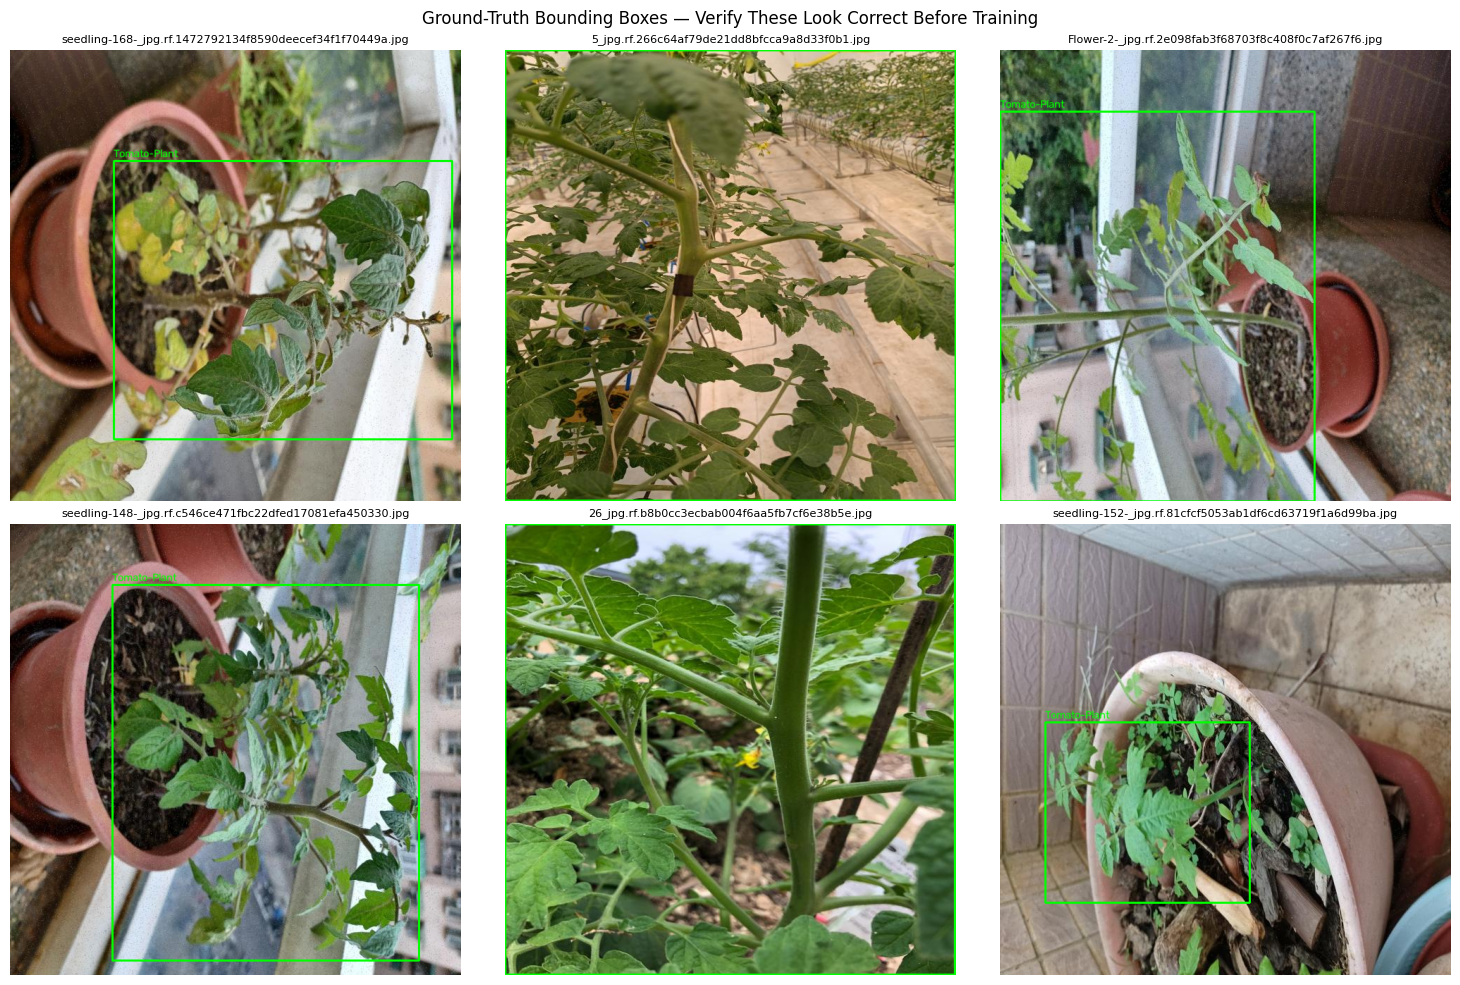

If boxes surround WHOLE plants, the dataset is correct for Module 2.


In [3]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import random

def draw_yolo_labels(image_path, label_path):
    """Draw YOLOv8 bounding boxes on an image."""
    img = cv2.imread(str(image_path))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]

    with open(label_path) as f:
        lines = f.readlines()

    for line in lines:
        parts = line.strip().split()
        cls_id, cx, cy, bw, bh = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])

        # Convert from normalised fractions to pixel coordinates
        x1 = int((cx - bw / 2) * w)
        y1 = int((cy - bh / 2) * h)
        x2 = int((cx + bw / 2) * w)
        y2 = int((cy + bh / 2) * h)

        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
        cv2.putText(img, 'Tomato-Plant', (x1, y1 - 5), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1)

    return img

train_images = list((DATASET_PATH / 'train' / 'images').glob('*.jpg'))
samples = random.sample(train_images, min(6, len(train_images)))

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.flatten(), samples):
    lbl_path = img_path.parent.parent / 'labels' / (img_path.stem + '.txt')
    img = draw_yolo_labels(img_path, lbl_path)
    ax.imshow(img)
    ax.set_title(img_path.name, fontsize=8)
    ax.axis('off')

plt.suptitle('Ground-Truth Bounding Boxes — Verify These Look Correct Before Training', fontsize=12)
plt.tight_layout()
plt.show()
print('If boxes surround WHOLE plants, the dataset is correct for Module 2.')

## Train YOLOv8n

**This is the main training cell.**

**Parameters explained:**

| Parameter | Value | Why |
|---|---|---|
| `model` | yolov8n.pt | Smallest variant; avoids overfitting on 546 images |
| `data` | data.yaml path | Tells YOLO where train/valid/test images are |
| `epochs` | 50 | Number of full passes through the training data |
| `imgsz` | 640 | YOLOv8 default; balances detail vs speed |
| `batch` | 8 | How many images per gradient update; use 4 if GPU < 4GB |
| `patience` | 15 | Stop early if no improvement for 15 epochs |
| `optimizer` | AdamW | Better than SGD for fine-tuning pretrained models |
| `lr0` | 0.001 | Starting learning rate |
| `augment` | True (default) | Random flips, crops, colour jitter — boosts generalisation |
| `project` | models/yolov8_plant_detector/runs | Where training outputs are saved |
| `name` | train_v1 | Sub-folder name for this run |

**Expected training time:** ~5–15 minutes on a modern CPU laptop for 50 epochs with 546 images.  
If you have a GPU, it will be under 2 minutes.

In [3]:
from ultralytics import YOLO
from pathlib import Path

REPO_ROOT = Path.cwd().parent  # notebooks/ -> SmartSpray/
YAML_PATH = REPO_ROOT / 'data' / 'datasets' / 'plant_detection' / 'data.yaml'
MODEL_DIR = REPO_ROOT / 'models' / 'yolov8_plant_detector'
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Load base YOLOv8n pretrained on COCO — weights auto-download on first run
model = YOLO('yolov8n.pt')

# Fine-tune on the tomato-plant dataset
results = model.train(
    data=str(YAML_PATH),
    epochs=50,
    imgsz=640,
    batch=8,
    patience=15,
    optimizer='AdamW',
    lr0=0.001,
    project=str(MODEL_DIR / 'runs'),
    name='train_v1',
    exist_ok=True,
    verbose=True
)

print('\n✅ Training complete.')
print(f'Best weights saved at: {results.save_dir}/weights/best.pt')

Matplotlib is building the font cache; this may take a moment.


Ultralytics 8.4.84  Python-3.12.4 torch-2.12.1+cpu CPU (12th Gen Intel Core i5-12450H)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=d:\RIDDHIMA SINGH\SmartSpray\data\datasets\plant_detection\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_v1, nbs=64, nms=False, opset=None, optimize=False,

## Evaluate on the test set

This runs the model on the held-out test images and prints metrics.

In [4]:
best_weights = MODEL_DIR / 'runs' / 'train_v1' / 'weights' / 'best.pt'
assert best_weights.exists(), f'best.pt not found at {best_weights}. Did training complete?'

trained_model = YOLO(str(best_weights))
metrics = trained_model.val(data=str(YAML_PATH), split='test')

print('\n=== TEST SET METRICS ===')
print(f'mAP@50      : {metrics.box.map50:.4f}   (target: > 0.80)')
print(f'mAP@50-95   : {metrics.box.map:.4f}   (informational)')
print(f'Precision   : {metrics.box.mp:.4f}')
print(f'Recall      : {metrics.box.mr:.4f}   (target: > 0.85 — missing plants is worse than false positives)')

if metrics.box.mr < 0.85:
    print('\n⚠️  Recall below target. Consider: more epochs, adding your own field photos, or reducing conf threshold during inference.')
else:
    print('\n✅ Metrics acceptable. Proceed to Cell 6.')

Ultralytics 8.4.84  Python-3.12.4 torch-2.12.1+cpu CPU (12th Gen Intel Core i5-12450H)
Model summary (fused): 73 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.50.2 ms, read: 3.40.8 MB/s, size: 76.0 KB)
val: Scanning D:\RIDDHIMA SINGH\SmartSpray\data\datasets\plant_detection\test\labels... 29 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 29/29 126.2it/s 0.2s.1s
val: New cache created: D:\RIDDHIMA SINGH\SmartSpray\data\datasets\plant_detection\test\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.7s/it 3.5s6.2s
                   all         29         34      0.995      0.912      0.919      0.763
Speed: 1.4ms preprocess, 98.8ms inference, 0.0ms loss, 1.3ms postprocess per image
Results saved to D:\RIDDHIMA SINGH\SmartSpray\notebooks\runs\detect\val

=== TEST SET METRICS ===
mAP@50      : 0.9192   (target: > 0.80)
mAP@50-95   : 0.7634   (informational)
Precision  

## Copy best.pt to the production location

The FastAPI detector loads from `models/yolov8_plant_detector/best.pt`.  
This cell copies the trained weights there.

In [5]:
import shutil

source = MODEL_DIR / 'runs' / 'train_v1' / 'weights' / 'best.pt'
destination = MODEL_DIR / 'best.pt'

shutil.copy2(source, destination)
print(f'✅ Copied: {source}')
print(f'       → {destination}')
print(f'File size: {destination.stat().st_size / 1024:.1f} KB')
print('\nThe FastAPI detector will now load this file on startup.')

✅ Copied: d:\RIDDHIMA SINGH\SmartSpray\models\yolov8_plant_detector\runs\train_v1\weights\best.pt
       → d:\RIDDHIMA SINGH\SmartSpray\models\yolov8_plant_detector\best.pt
File size: 6103.0 KB

The FastAPI detector will now load this file on startup.


## Run inference on a real survey image

This validates that the model works on your own field photos before wiring it into the API.

In [9]:
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

REPO_ROOT = Path.cwd().parent
MODEL_PATH = REPO_ROOT / 'models' / 'yolov8_plant_detector' / 'best.pt'

# --- Find a survey image to test on ---
survey_folder = REPO_ROOT / 'data' / 'images' / 'survey_001'
test_images = list(survey_folder.glob('*.jpg')) + list(survey_folder.glob('*.png'))

if not test_images:
    print(f'No images found in {survey_folder}')
    print('Place some test images there and re-run this cell.')
else:
    model = YOLO(str(MODEL_PATH))
    test_img = test_images[0]
    results = model(str(test_img), conf=0.25)

    result = results[0]
    annotated = result.plot()  # draws boxes on image
    annotated_rgb = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 8))
    plt.imshow(annotated_rgb)
    plt.title(f'{test_img.name} — {len(result.boxes)} plants detected')
    plt.axis('off')
    plt.show()

    print(f'Detections on {test_img.name}:')
    for i, box in enumerate(result.boxes):
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        conf = box.conf[0].item()
        print(f'  Plant {i+1}: bbox=[{x1:.0f},{y1:.0f},{x2:.0f},{y2:.0f}]  confidence={conf:.3f}')


image 1/1 d:\RIDDHIMA SINGH\SmartSpray\data\images\survey_001\photo1.jpg: 640x640 2 Tomato-Plants, 181.1ms
Speed: 9.0ms preprocess, 181.1ms inference, 2.7ms postprocess per image at shape (1, 3, 640, 640)


<Figure size 1200x800 with 1 Axes>

Detections on photo1.jpg:
  Plant 1: bbox=[103,7,656,467]  confidence=0.784
  Plant 2: bbox=[219,144,250,188]  confidence=0.523



#DO THIS STEP ONLY IF THE MODEL PERFORMS BELOW THE REQUIRED TARGETS USED, ELSE LEAVE IT

## Fine-tune on your own demo field photos

If Cell 7 shows poor detection on your real field photos, run this cell to continue training  
on a small set of your own annotated images.

Steps:
1. Annotate 20-30 of your own field photos on https://app.roboflow.com (free)
2. Export in YOLOv8 format
3. Place at `data/datasets/plant_detection_custom/`
4. Run this cell

#code
CUSTOM_YAML = REPO_ROOT / 'data' / 'datasets' / 'plant_detection_custom' / 'data.yaml'

if not CUSTOM_YAML.exists():
    print('No custom dataset found. Skipping. This is optional — only needed if Cell 7 showed poor results.')
else:
    # Start from the weights already trained in Cell 4
    finetuned_model = YOLO(str(MODEL_DIR / 'best.pt'))
    
    results = finetuned_model.train(
        data=str(CUSTOM_YAML),
        epochs=30,          # fewer epochs for a small custom set
        imgsz=640,
        batch=4,            # smaller batch for small dataset
        patience=10,
        optimizer='AdamW',
        lr0=0.0005,         # lower LR to avoid forgetting the public dataset
        project=str(MODEL_DIR / 'runs'),
        name='finetune_v1',
        exist_ok=True
    )

    # Copy updated weights
    new_best = MODEL_DIR / 'runs' / 'finetune_v1' / 'weights' / 'best.pt'
    shutil.copy2(new_best, MODEL_DIR / 'best.pt')
    print(f'\n✅ Fine-tuned weights copied to models/yolov8_plant_detector/best.pt')